# Policy Iteration

Policy iteration alternates an exact linear solve for the current policy with greedy improvement. The full transition model of a slippery grid is known.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Known dynamics

There are four actions. The intended move occurs with probability 0.84 and either sideways slip has probability 0.08.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gallery.gridworld import (
    S,
    A,
    GAMMA,
    START,
    choose,
    step,
    q_from_v,
    exact_values,
    policy_report,
)

## Solve the grid

Entering the goal pays 1, entering the pit costs 1 and an ordinary step costs 0.04. The discount factor is 0.95.

In [3]:
policy = np.zeros(S, dtype=int)
residuals = []
for sweep in range(100):
    v = exact_values(policy)
    q = q_from_v(v)
    residuals.append(abs(q.max(1) - v).max())
    improved = q.argmax(axis=1)
    if np.array_equal(improved, policy):
        break
    policy = improved
print(f"Policy evaluations {len(residuals)} | Bellman optimality residual {residuals[-1]:.3g}")

Policy evaluations 4 | Bellman optimality residual 2.22e-16


## Evaluate the policy

Independent rollouts measure success and return. The numeric start value also has an exact solution.

Seed exact: mean return 0.676, goal 98.8%, pit 1.2%, mean steps 8.5, exact discounted start value 0.416
Random policy: mean return -1.715, goal 15.8%, pit 70.0%, mean steps 30.2


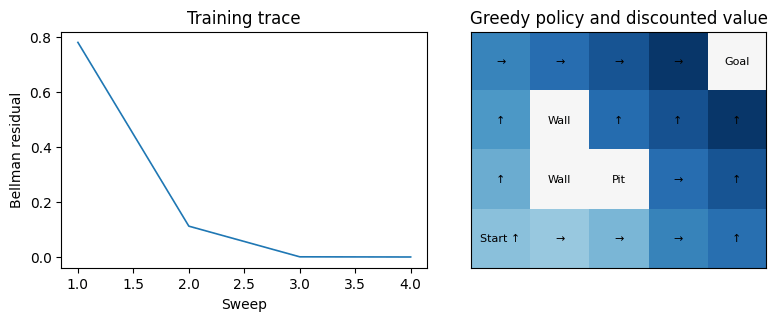

In [4]:
policy_report([("exact", policy)], [residuals], "Bellman residual", "Sweep")
plt.show()

## Reading the result

The heatmap contains discounted values. The simulated return is undiscounted and episodes stop at a terminal square or after sixty moves.

## References

[Sutton and Barto, Reinforcement Learning: An Introduction (2018)](https://mitpress.mit.edu/9780262039246/reinforcement-learning/)

[Grid dynamics and policy evaluation](../../../gallery/gridworld.py)